In [2]:
# %pip install tensorflow

In [6]:
import os
import tensorflow as tf
from tensorflow.keras import models, layers, callbacks
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report

### Préparation des dataset

In [2]:
data_dir = "../data/images"
img_height, img_width = 180, 180
batch_size = 32
seed = 42

class_names = sorted([d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d))])
print(f"{len(class_names)} classes détectées :", class_names)

file_paths = []
labels = []

# Parcourir les dossiers
for label_idx, class_name in enumerate(class_names):
    class_path = os.path.join(data_dir, class_name)
    for file in os.listdir(class_path):
        # On filtre STRICTEMENT sur les extensions d'images pour éviter le bug
        if file.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
            file_paths.append(os.path.join(class_path, file))
            labels.append(label_idx)

print(f"Total d'images valides trouvées : {len(file_paths)}")

# Créer le Dataset TensorFlow
list_ds = tf.data.Dataset.from_tensor_slices((file_paths, labels))
# Mélanger une première fois de manière fixe avec le seed
list_ds = list_ds.shuffle(buffer_size=len(file_paths), seed=seed, reshuffle_each_iteration=False)

# Séparation (80% Train, 10% Valid, 10% Test)
DATASET_SIZE = len(file_paths)
train_size = int(0.8 * DATASET_SIZE)
val_size = int(0.1 * DATASET_SIZE)

train_ds = list_ds.take(train_size)
rest_ds = list_ds.skip(train_size)
val_ds = rest_ds.take(val_size)
test_ds = rest_ds.skip(val_size)

# Charger et décoder les images à la volée
def process_path(file_path, label):
    img = tf.io.read_file(file_path)
    # decode_jpeg ou decode_image avec expand_animations=False gère le flux proprement
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, [img_height, img_width])
    return img, label

# Pipeline de performance (Batch, Shuffle, Prefetch)
AUTOTUNE = tf.data.AUTOTUNE

def prepare_dataset(ds, shuffle=False):
    ds = ds.map(process_path, num_parallel_calls=AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(buffer_size=1000)
    ds = ds.batch(batch_size)
    return ds.prefetch(buffer_size=AUTOTUNE)

train_ds = prepare_dataset(train_ds, shuffle=True)
val_ds = prepare_dataset(val_ds)
test_ds = prepare_dataset(test_ds)

print(f"Structure finalisée avec succès !")
print(f"Nombre de batches -> Train: {len(train_ds)}, Valid: {len(val_ds)}, Test: {len(test_ds)}")


6 classes détectées : ['biscuits', 'cereales', 'chips', 'chocolats', 'pates', 'pizzas']
Total d'images valides trouvées : 3000
Structure finalisée avec succès !
Nombre de batches -> Train: 75, Valid: 10, Test: 10


In [3]:
print(f"NOMBRE TOTAL D'IMAGES : {DATASET_SIZE}")
print(f"Train : {train_size} images")
print(f"Validation : {val_size} images")
print(f"Test : {DATASET_SIZE - train_size - val_size} images")

NOMBRE TOTAL D'IMAGES : 3000
Train : 2400 images
Validation : 300 images
Test : 300 images


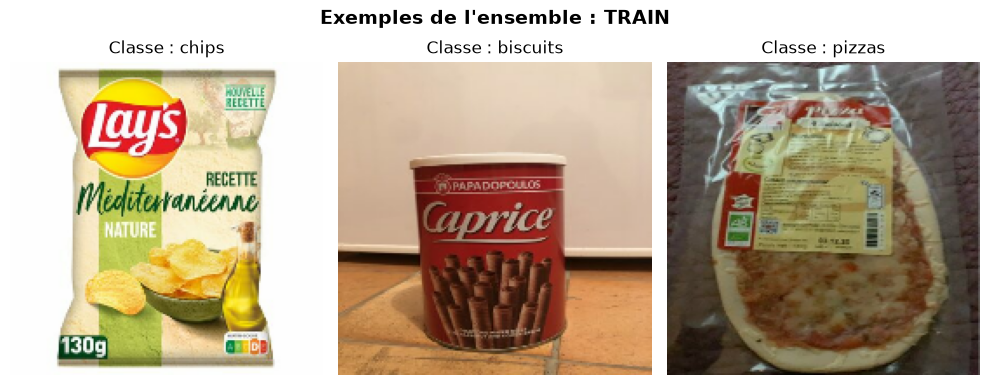

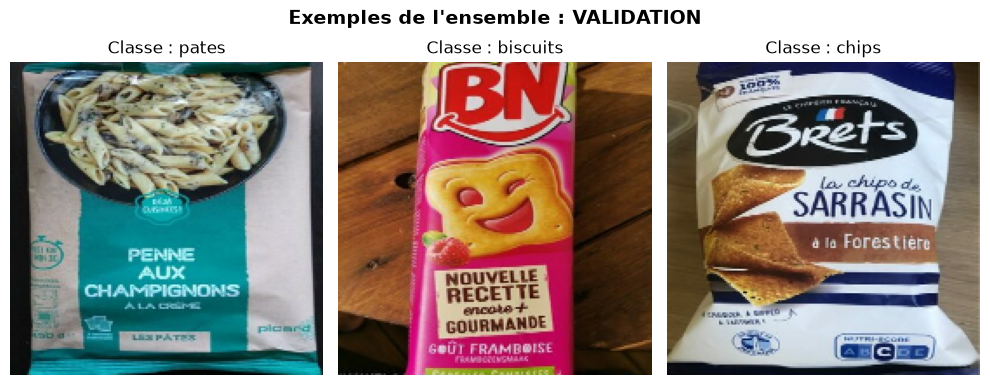

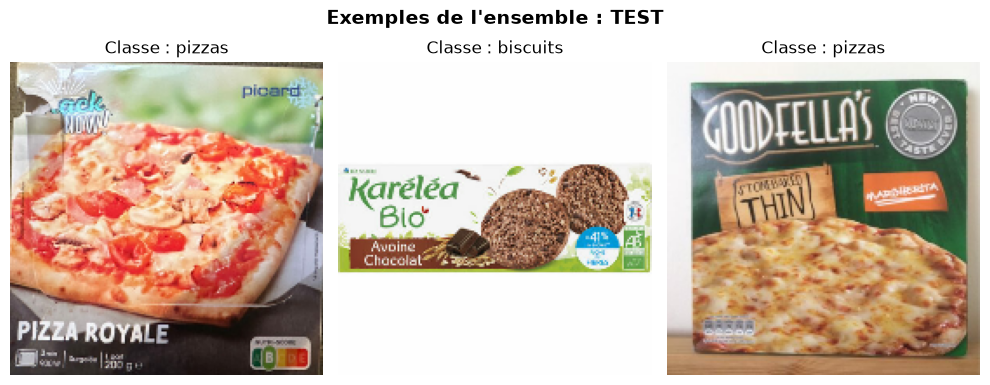

In [4]:
# Dictionnaire pour convertir l'index numérique en nom de classe textuel
labels_to_names = {idx: name for idx, name in enumerate(class_names)}

def afficher_images_du_set(dataset, nom_du_set):
    # Récupérer un seul batch d'images et de labels
    for images, labels in dataset.take(1):
        plt.figure(figsize=(10, 4))
        plt.suptitle(f"Exemples de l'ensemble : {nom_du_set}", fontsize=14, fontweight='bold')
        
        # Afficher les 3 premières images du batch
        for i in range(3):
            plt.subplot(1, 3, i + 1)
            
            # TensorFlow stocke les images en float32 après le resize. 
            # On convertit en uint8 (0-255) pour l'affichage matplotlib.
            img = images[i].numpy().astype("uint8")
            plt.imshow(img)
            
            # Récupérer le nom de la classe
            label_idx = int(labels[i].numpy())
            classe_name = labels_to_names[label_idx]
            
            plt.title(f"Classe : {classe_name}")
            plt.axis("off")
        
        plt.tight_layout()
        plt.show()

afficher_images_du_set(train_ds, "TRAIN")
afficher_images_du_set(val_ds, "VALIDATION")
afficher_images_du_set(test_ds, "TEST")

### Definition du Modèle CNN

In [5]:
def build_cnn(num_classes=6):  # Configuré par défaut pour 6 répertoires
    model = models.Sequential([
        # --- Forme d'entrée adaptée à vos images (180x180 pixels, 3 canaux RGB) ---
        layers.Input(shape=(180, 180, 3)),

        # [Optionnel] Couche de normalisation intégrée pour passer les pixels de [0-255] à [0-1]
        layers.Rescaling(1./255),

        # --- Bloc 1 ---
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),   # 180x180 → 90x90
        layers.Dropout(0.25),

        # --- Bloc 2 ---
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),   # 90x90 → 45x45
        layers.Dropout(0.25),
        
        # --- Bloc 3 (Ajouté pour gérer la plus grande résolution d'image) ---
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),   # 45x45 → 22x22
        layers.Dropout(0.25),

        # --- Tête de classification ---
        layers.Flatten(),              
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ], name='CNN_Images_NS')

    # Compilation avec 'sparse_categorical_crossentropy' adaptée aux labels entiers
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy', 
        metrics=['accuracy']
    )
    return model

model = build_cnn(num_classes=len(class_names))
model.summary()


Model: "CNN_Images_NS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 180, 180, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 90, 90, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 61952)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,929,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,070,182 (30.79 MB)

 Trainable params: 8,070,182 (30.79 MB)

 Non-trainable params: 0 (0.00 B)

### Entrainement avec Callbacks

In [6]:
os.makedirs('../data/checkpoints', exist_ok=True)

early_stop = callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=8,
    restore_best_weights=True, 
    verbose=1
)

model_ckpt = callbacks.ModelCheckpoint(
    filepath='../data/checkpoints/cnn_images.keras',
    monitor='val_accuracy', 
    save_best_only=True, 
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    shuffle=False,
    verbose=1,
    callbacks=[early_stop, model_ckpt]
)

Epoch 1/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 451ms/step - accuracy: 0.1704 - loss: 1.9630
Epoch 1: val_accuracy improved from None to 0.16000, saving model to ../data/checkpoints/cnn_images.keras

Epoch 1: finished saving model to ../data/checkpoints/cnn_images.keras
75/75 ━━━━━━━━━━━━━━━━━━━━ 37s 476ms/step - accuracy: 0.1704 - loss: 1.9630 - val_accuracy: 0.1600 - val_loss: 1.7921
Epoch 2/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 450ms/step - accuracy: 0.1717 - loss: 1.7923
Epoch 2: val_accuracy did not improve from 0.16000
75/75 ━━━━━━━━━━━━━━━━━━━━ 35s 467ms/step - accuracy: 0.1717 - loss: 1.7923 - val_accuracy: 0.1567 - val_loss: 1.7921
Epoch 3/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 448ms/step - accuracy: 0.1692 - loss: 1.7917
Epoch 3: val_accuracy did not improve from 0.16000
75/75 ━━━━━━━━━━━━━━━━━━━━ 35s 465ms/step - accuracy: 0.1692 - loss: 1.7917 - val_accuracy: 0.1567 - val_loss: 1.7925
Epoch 4/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 449ms/step - accuracy: 0.1787 - loss: 1.7915
Epoch 4: val_accuracy 

### Evaluation du Modèle

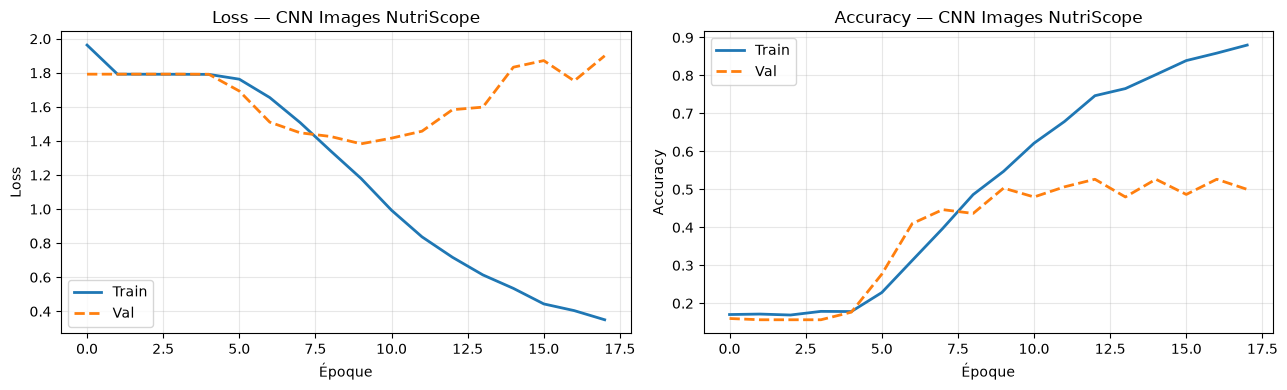

In [7]:
def plot_loss_acc(history, title=''):
    """Trace les courbes de loss et d'accuracy pour suivre l'entraînement."""
    _, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

    # --- Graphique de la Perte (Loss) ---
    ax1.plot(history.history['loss'],     label='Train', linewidth=2)
    ax1.plot(history.history['val_loss'], label='Val',   linewidth=2, linestyle='--')
    ax1.set_title(f'Loss {title}'); ax1.set_xlabel('Époque'); ax1.set_ylabel('Loss')
    ax1.legend(); ax1.grid(alpha=0.3)

    # --- Graphique de la Précision (Accuracy) ---
    ax2.plot(history.history['accuracy'],     label='Train', linewidth=2)
    ax2.plot(history.history['val_accuracy'], label='Val',   linewidth=2, linestyle='--')
    ax2.set_title(f'Accuracy {title}'); ax2.set_xlabel('Époque'); ax2.set_ylabel('Accuracy')
    ax2.legend(); ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_loss_acc(history, '— CNN Images NutriScope')


In [8]:
# Évaluation globale sur le dataset de test
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc:.4f}  ({test_acc*100:.2f}%)")

# Récupérer les prédictions du modèle sur l'ensemble de test
print("\nCalcul des prédictions...")
y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)

# Extraire les vrais labels (y_true) stockés à l'intérieur du tf.data.Dataset de test
y_true = []
for _, labels in test_ds:
    y_true.extend(labels.numpy())
y_true = np.array(y_true)

# Affichage du rapport complet
print("\nClassification Report :")
print(classification_report(y_true, y_pred, target_names=class_names))


Test Loss     : 1.3756
Test Accuracy : 0.4767  (47.67%)

Calcul des prédictions...

Classification Report :
              precision    recall  f1-score   support

    biscuits       0.40      0.36      0.38        45
    cereales       0.46      0.32      0.38        53
       chips       0.55      0.36      0.43        50
   chocolats       0.53      0.69      0.60        59
       pates       0.43      0.52      0.47        42
      pizzas       0.47      0.57      0.51        51

    accuracy                           0.48       300
   macro avg       0.47      0.47      0.46       300
weighted avg       0.48      0.48      0.47       300



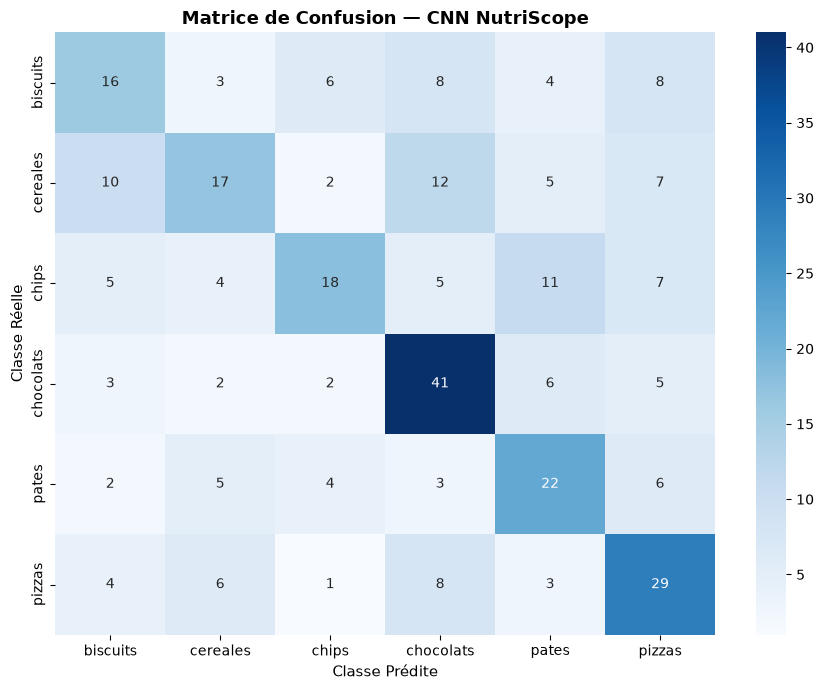

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Matrice de confusion en utilisant les vrais labels (y_true)
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)

plt.title("Matrice de Confusion — CNN NutriScope", fontsize=13, fontweight='bold')
plt.xlabel("Classe Prédite", fontsize=11)
plt.ylabel("Classe Réelle", fontsize=11)
plt.tight_layout()
plt.show()

### Data Augmentation

In [10]:
def build_cnn_augmented(num_classes=6):
    model_aug = models.Sequential([
        # 180x180 pixels, 3 canaux RGB
        layers.Input(shape=(180, 180, 3)),

        # Data Augmentation — actif uniquement pendant l'entraînement
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.05),
        layers.RandomTranslation(0.05, 0.05),

        # [Optionnel] Couche de normalisation intégrée pour passer les pixels de [0-255] à [0-1]
        layers.Rescaling(1./255),

        # --- Bloc 1 ---
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),   # 180x180 → 90x90
        layers.Dropout(0.25),

        # --- Bloc 2 ---
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),   # 90x90 → 45x45
        layers.Dropout(0.25),
        
        # --- Bloc 3 (Ajouté pour gérer la plus grande résolution d'image) ---
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),   # 45x45 → 22x22
        layers.Dropout(0.25),

        # --- Tête de classification ---
        layers.Flatten(),              
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ], name='CNN_Images_NS')

    # Compilation avec 'sparse_categorical_crossentropy' adaptée aux labels entiers
    model_aug.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy', 
        metrics=['accuracy']
    )
    return model

# Initialisation du modèle pour vos 6 classes
model_aug = build_cnn_augmented(num_classes=len(class_names))
model_aug.summary()


Model: "CNN_Images_NS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 180, 180, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 90, 90, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 61952)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,929,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,210,548 (92.36 MB)

 Trainable params: 8,070,182 (30.79 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 16,140,366 (61.57 MB)

In [11]:
os.makedirs('../data/checkpoints', exist_ok=True)

early_stop_aug = callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=8,
    restore_best_weights=True, 
    verbose=1
)

model_ckpt_aug = callbacks.ModelCheckpoint(
    filepath='../data/checkpoints/cnn_images_aug.keras',
    monitor='val_accuracy', 
    save_best_only=True, 
    verbose=1
)

history_aug = model_aug.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    shuffle=False,
    verbose=1,
    callbacks=[early_stop_aug, model_ckpt_aug]
)

loss_aug, acc_aug = model_aug.evaluate(test_ds, verbose=0)
print(f"\nTest Loss (avec augmentation)     : {loss_aug:.4f}")
print(f"Test Accuracy (avec augmentation) : {acc_aug:.4f}  ({acc_aug*100:.2f}%)")

Epoch 1/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 441ms/step - accuracy: 0.6442 - loss: 0.9402
Epoch 1: val_accuracy improved from None to 0.46333, saving model to ../data/checkpoints/cnn_images_aug.keras

Epoch 1: finished saving model to ../data/checkpoints/cnn_images_aug.keras
75/75 ━━━━━━━━━━━━━━━━━━━━ 35s 464ms/step - accuracy: 0.6442 - loss: 0.9402 - val_accuracy: 0.4633 - val_loss: 1.4812
Epoch 2/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 460ms/step - accuracy: 0.6842 - loss: 0.8458
Epoch 2: val_accuracy improved from 0.46333 to 0.47000, saving model to ../data/checkpoints/cnn_images_aug.keras

Epoch 2: finished saving model to ../data/checkpoints/cnn_images_aug.keras
75/75 ━━━━━━━━━━━━━━━━━━━━ 36s 482ms/step - accuracy: 0.6842 - loss: 0.8458 - val_accuracy: 0.4700 - val_loss: 1.4069
Epoch 3/20
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 456ms/step - accuracy: 0.7312 - loss: 0.7398
Epoch 3: val_accuracy improved from 0.47000 to 0.51000, saving model to ../data/checkpoints/cnn_images_aug.keras

Epoch 3: finished

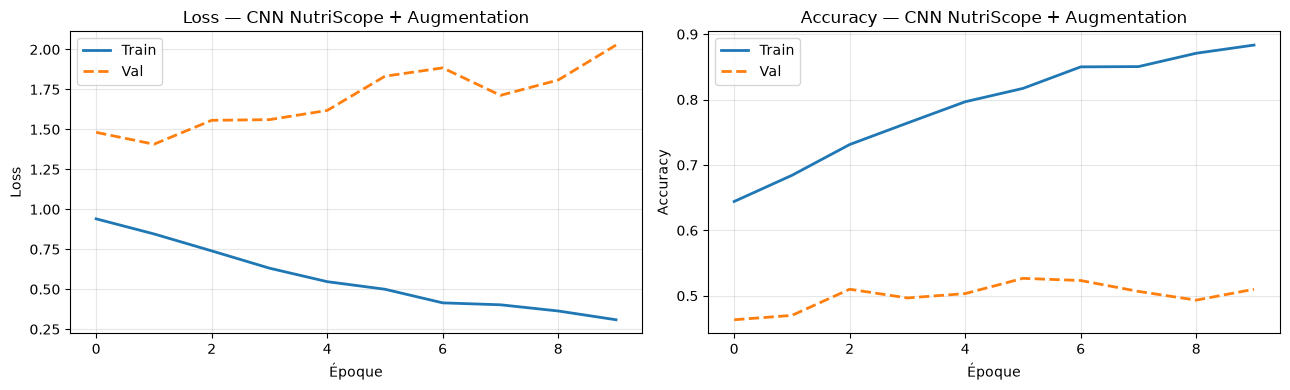

=================== Comparaison ===================
CNN de base (sans augmentation) : 0.4767 (47.67%)
CNN final   (avec augmentation) : 0.4867 (48.67%)


In [12]:
plot_loss_acc(history_aug, '— CNN NutriScope + Augmentation')

print("=================== Comparaison ===================")
print(f"CNN de base (sans augmentation) : {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"CNN final   (avec augmentation) : {acc_aug:.4f} ({acc_aug*100:.2f}%)")
print("===================================================")

### Architecture du modèle

In [13]:
def build_feature_extraction_model(num_classes=6):
    # Chargement de MobileNetV2 configuré pour une taille native optimale (160x160)
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(160, 160, 3),  # Résolution d'entrée pour MobileNetV2
        include_top=False,          # Retrait de la couche de classification ImageNet
        weights='imagenet'          # Utilisation des poids pré-entraînés
    )
    # Geler TOUTES les couches de MobileNetV2 pour ne pas détruire les poids appris
    base_model.trainable = False

    # Construction du modèle avec le format d'entrée actuel (180x180)
    inp = tf.keras.Input(shape=(180, 180, 3), name='input_image')

    # Prétraitement intégré : Redimensionnement en 160x160
    x = layers.Resizing(160, 160, name='resize')(inp)
    
    # Prétraitement MobileNetV2 standardisé : conversion des pixels [0-255] vers l'intervalle [-1, 1]
    x = layers.Rescaling(scale=1/127.5, offset=-1.0, name='preprocess')(x)

    # Extraction de features (poids gelés)
    # training=False maintient les couches de BatchNorm figées (crucial pour le Feature Extraction)
    x = base_model(x, training=False)

    # Tête de classification personnalisée pour les 6 classes
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.Dropout(0.3, name='dropout')(x)
    out = layers.Dense(num_classes, activation='softmax', name='predictions')(x)

    # Assemblage du modèle final
    model = tf.keras.Model(inp, out, name='TransferModel_FeatureExtraction')
    
    return model, base_model

# Initialisation avec classes réelles
model_fe, base_model = build_feature_extraction_model(num_classes=len(class_names))

# Calcul et affichage des statistiques des paramètres
total_p      = model_fe.count_params()
trainable_p  = sum(tf.keras.backend.count_params(w) for w in model_fe.trainable_weights)
frozen_p     = total_p - trainable_p

print(f"================ Paramètres MobilenetV2 ================")
print(f"Paramètres totaux MobileNetV2 + tête : {total_p:>10,}")
print(f"  → Entraînables (tête uniquement)   : {trainable_p:>10,}")
print(f"  → Gelés (base MobileNetV2)         : {frozen_p:>10,}")
print(f"  → Ratio entraîné / total           : {trainable_p/total_p*100:.2f}%")
print(f"=========================================================")


================ Paramètres MobilenetV2 ================
Paramètres totaux MobileNetV2 + tête :  2,265,670
  → Entraînables (tête uniquement)   :      7,686
  → Gelés (base MobileNetV2)         :  2,257,984
  → Ratio entraîné / total           : 0.34%


In [14]:
model_fe.summary()

Model: "TransferModel_FeatureExtraction"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resize (Resizing)               │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocess (Rescaling)          │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Entrainement

In [15]:
os.makedirs('../data/checkpoints', exist_ok=True)

# Compilation adaptée aux labels entiers
model_fe.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop_fe = callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=8, 
    restore_best_weights=True, 
    verbose=1
)

ckpt_fe = callbacks.ModelCheckpoint(
    filepath='../data/checkpoints/cnn_images_fe.keras',
    monitor='val_accuracy', 
    save_best_only=True, 
    verbose=1
)

# Lancement de la Phase 1 : Entraînement de la tête uniquement
print("=" * 60)
print("Phase 1 : Feature Extraction (MobileNetV2)")
print("Seule la tête de classification personnalisée est entraînée.")
print("=" * 60)

history_fe = model_fe.fit(
    train_ds,                  # Flux tf.data d'entraînement (batching et shuffle déjà inclus)
    validation_data=val_ds,    # Flux tf.data de validation
    epochs=15,
    shuffle=False,             # Géré nativement par notre train_ds
    verbose=1,
    callbacks=[early_stop_fe, ckpt_fe]
)

# Évaluation finale sur l'ensemble de test isolé
loss_fe, acc_fe = model_fe.evaluate(test_ds, verbose=0)
print(f"\n✓ Phase 1 terminée — Test Accuracy : {acc_fe:.4f} ({acc_fe*100:.2f}%)")

Phase 1 : Feature Extraction (MobileNetV2)
Seule la tête de classification personnalisée est entraînée.
Epoch 1/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - accuracy: 0.4479 - loss: 1.4891
Epoch 1: val_accuracy improved from None to 0.64667, saving model to ../data/checkpoints/cnn_images_fe.keras

Epoch 1: finished saving model to ../data/checkpoints/cnn_images_fe.keras
75/75 ━━━━━━━━━━━━━━━━━━━━ 17s 187ms/step - accuracy: 0.4479 - loss: 1.4891 - val_accuracy: 0.6467 - val_loss: 1.0231
Epoch 2/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step - accuracy: 0.6787 - loss: 0.9053
Epoch 2: val_accuracy improved from 0.64667 to 0.69000, saving model to ../data/checkpoints/cnn_images_fe.keras

Epoch 2: finished saving model to ../data/checkpoints/cnn_images_fe.keras
75/75 ━━━━━━━━━━━━━━━━━━━━ 14s 187ms/step - accuracy: 0.6787 - loss: 0.9053 - val_accuracy: 0.6900 - val_loss: 0.9080
Epoch 3/15
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step - accuracy: 0.7304 - loss: 0.7686
Epoch 3: val_accuracy improved 

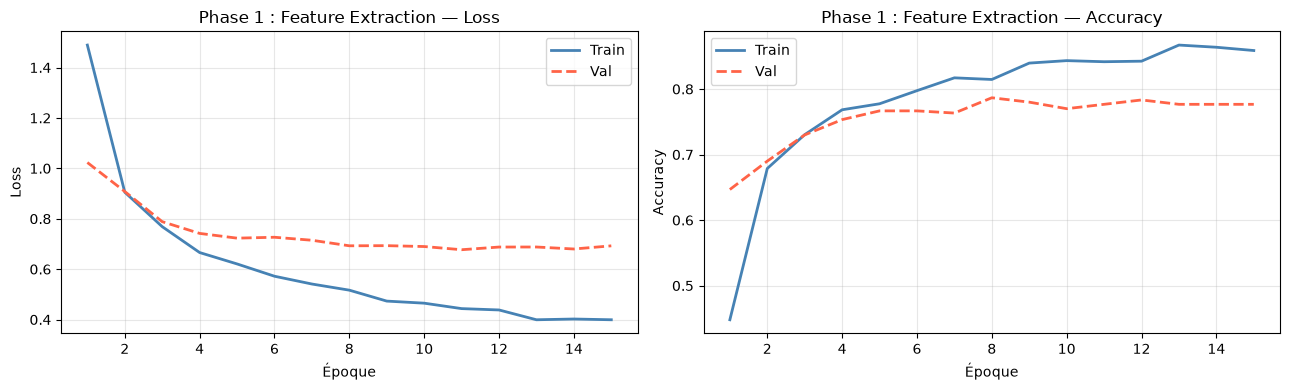

In [16]:
def plot_history(history, title, color_train='steelblue', color_val='tomato'):
    """Trace les courbes de loss et accuracy."""
    _, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
    epochs = range(1, len(history.history['loss']) + 1)

    ax1.plot(epochs, history.history['loss'],     color=color_train, label='Train', linewidth=2)
    ax1.plot(epochs, history.history['val_loss'], color=color_val, linestyle='--', label='Val', linewidth=2)
    ax1.set_title(f'{title} — Loss'); ax1.set_xlabel('Époque'); ax1.set_ylabel('Loss')
    ax1.legend(); ax1.grid(alpha=0.3)

    ax2.plot(epochs, history.history['accuracy'],     color=color_train, label='Train', linewidth=2)
    ax2.plot(epochs, history.history['val_accuracy'], color=color_val, linestyle='--', label='Val', linewidth=2)
    ax2.set_title(f'{title} — Accuracy'); ax2.set_xlabel('Époque'); ax2.set_ylabel('Accuracy')
    ax2.legend(); ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_history(history_fe, 'Phase 1 : Feature Extraction', 'steelblue', 'tomato')

### Fine-Tuning

In [18]:
# Charger le meilleur modèle de la phase FE
model_ft = tf.keras.models.load_model('../data/checkpoints/cnn_images_fe.keras')

# Retrouver le modèle de base (MobileNetV2)
base = next(l for l in model_ft.layers if 'mobilenet' in l.name.lower())
print(f"Modèle de base trouvé : {base.name}")
print(f"Nombre total de couches : {len(base.layers)}")

# Dégeler les 30 dernières couches
base.trainable = True
N_UNFREEZE = 30
for layer in base.layers[:-N_UNFREEZE]:
    layer.trainable = False

frozen    = sum(1 for l in base.layers if not l.trainable)
unfrozen  = sum(1 for l in base.layers if l.trainable)
trainable_p_ft = sum(tf.keras.backend.count_params(w) for w in model_ft.trainable_weights)

print(f"\nCouches gelées   : {frozen}")
print(f"Couches dégelées : {unfrozen} (dernières {N_UNFREEZE})")
print(f"Paramètres entraînables (FT) : {trainable_p_ft:,}")

Modèle de base trouvé : mobilenetv2_1.00_160
Nombre total de couches : 154

Couches gelées   : 124
Couches dégelées : 30 (dernières 30)
Paramètres entraînables (FT) : 1,534,086


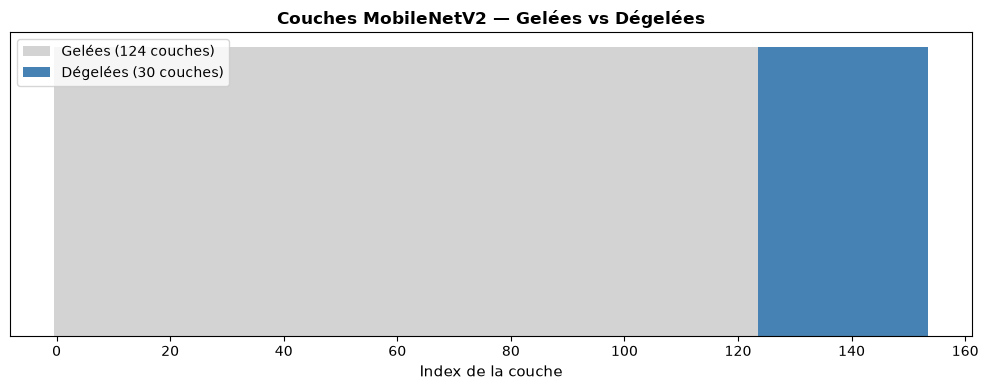

In [20]:
# Visualisation des couches gelées vs dégelées
fig, ax = plt.subplots(figsize=(10, 4))

trainable_flags = [l.trainable for l in base.layers]
colors = ['steelblue' if t else 'lightgray' for t in trainable_flags]

ax.bar(range(len(trainable_flags)), [1]*len(trainable_flags), color=colors, width=1.0)
ax.set_xlabel('Index de la couche', fontsize=11)
ax.set_title('Couches MobileNetV2 — Gelées vs Dégelées', fontsize=12, fontweight='bold')
ax.set_yticks([])

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='lightgray', label=f'Gelées ({frozen} couches)'),
    Patch(facecolor='steelblue', label=f'Dégelées ({unfrozen} couches)')
]
ax.legend(handles=legend_elements, loc='upper left', fontsize=10)
plt.tight_layout()
plt.show()

In [39]:
os.makedirs('../data/checkpoints', exist_ok=True)

# Recompiler avec un learning rate très faible
model_ft.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),  # 100× plus faible qu'en FE
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop_ft = callbacks.EarlyStopping(
    monitor='val_loss', patience=8, restore_best_weights=True, verbose=1
)
ckpt_ft = callbacks.ModelCheckpoint(
    filepath='../data/checkpoints/cnn_images_ft.keras',
    monitor='val_accuracy', save_best_only=True, verbose=0
)

print("=" * 60)
print("Phase 2 : Fine-Tuning")
print(f"LR = 1e-5 (vs 1e-3 en FE) — 30 dernières couches dégelées")
print("=" * 60)

history_ft = model_ft.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    shuffle=False,
    verbose=1,
    callbacks=[early_stop_ft, ckpt_ft]
)

loss_ft, acc_ft = model_ft.evaluate(test_ds, verbose=0)
print(f"\n✓ Phase 2 terminée — Test Accuracy : {acc_ft:.4f} ({acc_ft*100:.2f}%)")

Phase 2 : Fine-Tuning
LR = 1e-5 (vs 1e-3 en FE) — 30 dernières couches dégelées
Epoch 1/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 26s 256ms/step - accuracy: 0.8504 - loss: 0.4164 - val_accuracy: 0.7600 - val_loss: 0.7093
Epoch 2/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 17s 224ms/step - accuracy: 0.8779 - loss: 0.3590 - val_accuracy: 0.7600 - val_loss: 0.7075
Epoch 3/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 17s 221ms/step - accuracy: 0.8892 - loss: 0.3180 - val_accuracy: 0.7500 - val_loss: 0.7041
Epoch 4/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 17s 229ms/step - accuracy: 0.9054 - loss: 0.2910 - val_accuracy: 0.7533 - val_loss: 0.7007
Epoch 5/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 18s 239ms/step - accuracy: 0.9162 - loss: 0.2724 - val_accuracy: 0.7433 - val_loss: 0.6885
Epoch 6/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 19s 243ms/step - accuracy: 0.9246 - loss: 0.2418 - val_accuracy: 0.7467 - val_loss: 0.6821
Epoch 7/10
75/75 ━━━━━━━━━━━━━━━━━━━━ 18s 240ms/step - accuracy: 0.9275 - loss: 0.2319 - val_accuracy: 0.7533 - val_loss: 0.6791
Epoch 8/10
75/75 

### Comparaison des Résultats

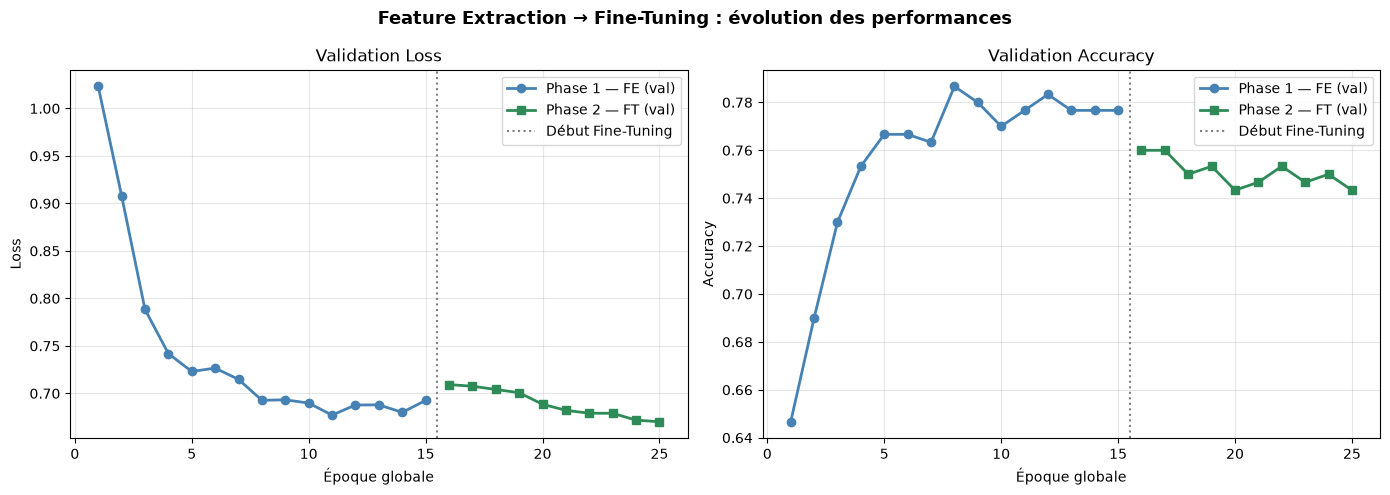

In [40]:
# Courbes combinées : FE + FT
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Épochs FE
e_fe = range(1, len(history_fe.history['val_accuracy'])+1)
e_ft = range(
    len(history_fe.history['val_accuracy'])+1,
    len(history_fe.history['val_accuracy'])+len(history_ft.history['val_accuracy'])+1
)

for ax, key, ylabel in [(ax1, 'val_loss', 'Loss'), (ax2, 'val_accuracy', 'Accuracy')]:
    ax.plot(e_fe, history_fe.history[key], 'o-', color='steelblue', label='Phase 1 — FE (val)', linewidth=2)
    ax.plot(e_ft, history_ft.history[key], 's-', color='seagreen',  label='Phase 2 — FT (val)', linewidth=2)
    ax.axvline(x=max(e_fe)+0.5, color='gray', linestyle=':', linewidth=1.5, label='Début Fine-Tuning')
    ax.set_xlabel('Époque globale'); ax.set_ylabel(ylabel)
    ax.set_title(f'Validation {ylabel}'); ax.legend(); ax.grid(alpha=0.3)

plt.suptitle("Feature Extraction → Fine-Tuning : évolution des performances",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [41]:
# Tableau comparatif
best_fe_val = max(history_fe.history['val_accuracy'])
best_ft_val = max(history_ft.history['val_accuracy'])

print("=" * 55)
print(f"{'Méthode':<30} {'Val Acc':>10} {'Test Acc':>10}")
print("-" * 55)
print(f"{'Phase 1 — Feature Extraction':<30} {best_fe_val:>10.4f} {acc_fe:>10.4f}")
print(f"{'Phase 2 — Fine-Tuning':<30} {best_ft_val:>10.4f} {acc_ft:>10.4f}")
print("=" * 55)
print(f"\nGain du Fine-Tuning : {(acc_ft - acc_fe)*100:+.2f}% en test")
print(f"Le Transfer Learning atteint ~{acc_ft*100:.0f}%")

Méthode                           Val Acc   Test Acc
-------------------------------------------------------
Phase 1 — Feature Extraction       0.7867     0.7867
Phase 2 — Fine-Tuning              0.7600     0.8067

Gain du Fine-Tuning : +2.00% en test
Le Transfer Learning atteint ~81%


#### Évaluation Détaillée du Meilleur Modèle

In [28]:
# Extraire les images et les vrais labels du flux tf.data.Dataset
all_images = []
y_true = []

for imgs, lbls in test_ds:
    all_images.append(imgs.numpy())
    y_true.extend(lbls.numpy())

all_images = np.concatenate(all_images, axis=0)
y_true = np.array(y_true)

In [42]:
# Charger le meilleur modèle FT
best_model = tf.keras.models.load_model('checkpoints/cnn_images_ft.keras')

y_pred = np.argmax(best_model.predict(test_ds, verbose=0), axis=1)

print("Classification Report :")
print(classification_report(y_true, y_pred, target_names=class_names))

Classification Report :
              precision    recall  f1-score   support

    biscuits       0.75      0.73      0.74        45
    cereales       0.80      0.68      0.73        53
       chips       0.65      0.88      0.75        50
   chocolats       0.86      0.95      0.90        59
       pates       0.68      0.50      0.58        42
      pizzas       0.96      0.88      0.92        51

    accuracy                           0.78       300
   macro avg       0.78      0.77      0.77       300
weighted avg       0.79      0.78      0.78       300



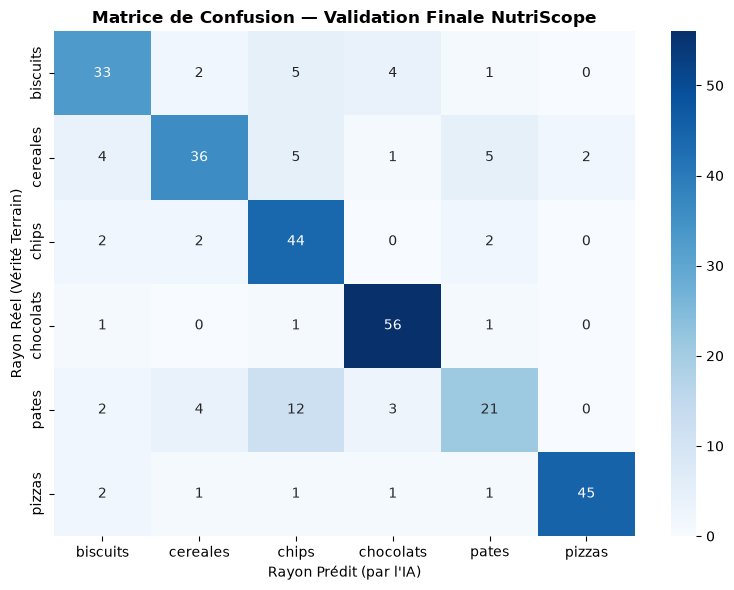

In [43]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title("Matrice de Confusion — Validation Finale NutriScope", fontsize=12, fontweight='bold')
plt.xlabel("Rayon Prédit (par l'IA)")
plt.ylabel("Rayon Réel (Vérité Terrain)")
plt.tight_layout()
plt.show()

In [44]:
print("\nACCURACY PAR RAYON :")
print("-" * 40)
cm = confusion_matrix(y_true, y_pred)
accuracy_par_rayon = cm.diagonal() / cm.sum(axis=1)

for idx, name in enumerate(class_names):
    print(f"Rayon {name.upper():<12} : {accuracy_par_rayon[idx]*100:.2f}% de bonnes prédictions")
print("-" * 40)


ACCURACY PAR RAYON :
----------------------------------------
Rayon BISCUITS     : 73.33% de bonnes prédictions
Rayon CEREALES     : 67.92% de bonnes prédictions
Rayon CHIPS        : 88.00% de bonnes prédictions
Rayon CHOCOLATS    : 94.92% de bonnes prédictions
Rayon PATES        : 50.00% de bonnes prédictions
Rayon PIZZAS       : 88.24% de bonnes prédictions
----------------------------------------



Génération de la planche des 6 pires confusions :
Erreur #1 : Une photo appartenant au rayon 'CEREALES' a été prise pour du 'BISCUITS' avec une fausse certitude de 89.41%.
Erreur #2 : Une photo appartenant au rayon 'CEREALES' a été prise pour du 'PIZZAS' avec une fausse certitude de 88.87%.
Erreur #3 : Une photo appartenant au rayon 'PATES' a été prise pour du 'CHIPS' avec une fausse certitude de 84.56%.
Erreur #4 : Une photo appartenant au rayon 'PIZZAS' a été prise pour du 'BISCUITS' avec une fausse certitude de 83.27%.
Erreur #5 : Une photo appartenant au rayon 'PATES' a été prise pour du 'CHOCOLATS' avec une fausse certitude de 80.71%.
Erreur #6 : Une photo appartenant au rayon 'CHIPS' a été prise pour du 'BISCUITS' avec une fausse certitude de 78.28%.


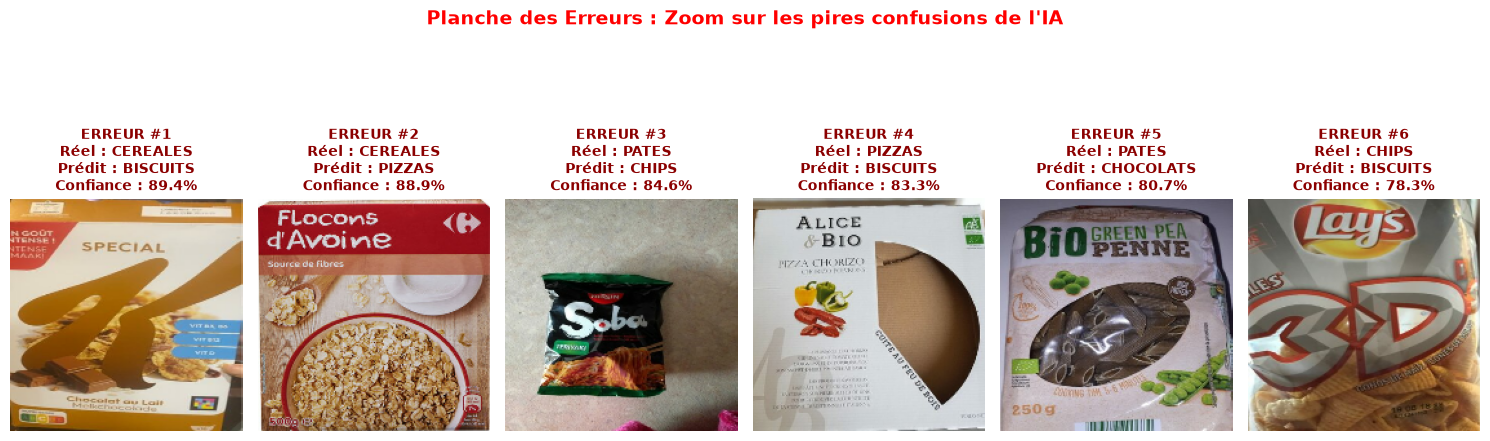

In [45]:
NB_ERROR_SHOW = 6

y_pred_probs = model_fe.predict(test_ds, verbose=0)

# Trouver les index où l'IA s'est trompée
indices_erreurs = np.where(y_pred != y_true)[0]

if len(indices_erreurs) == 0:
    print("Le modèle n'a commis aucune erreur sur l'ensemble de test.")
else:
    # Calculer le niveau de certitude de l'erreur (l'IA était très sûre d'elle mais s'est trompée)
    confiance_erreurs = [y_pred_probs[i, y_pred[i]] for i in indices_erreurs]
    # Trier pour obtenir les erreurs les plus flagrantes / confiantes
    pires_indices = indices_erreurs[np.argsort(confiance_erreurs)[::-1]]

    # Afficher les erreurs majeures sous forme de planche
    nb_a_afficher = min(NB_ERROR_SHOW, len(pires_indices))
    fig, axes = plt.subplots(1, nb_a_afficher, figsize=(15, 6))
    if nb_a_afficher == 1: axes = [axes] # Gestion du cas où il n'y a qu'une erreur
    
    print(f"\nGénération de la planche des {nb_a_afficher} pires confusions :")
    
    for col, idx in enumerate(pires_indices[:nb_a_afficher]):
        # Préparer l'image pour affichage matplotlib (uint8)
        img_out = all_images[idx].astype("uint8")
        
        real_class = labels_to_names[y_true[idx]].upper()
        pred_class = labels_to_names[y_pred[idx]].upper()
        confiance_fausse = y_pred_probs[idx, y_pred[idx]] * 100
        
        # Plot de l'image
        axes[col].imshow(img_out)
        axes[col].set_title(f"ERREUR #{col+1}\nRéel : {real_class}\nPrédit : {pred_class}\nConfiance : {confiance_fausse:.1f}%", 
                            color='darkred', fontsize=10, fontweight='bold')
        axes[col].axis('off')
        
        # Commentaire automatique de l'erreur dans la console
        print(f"Erreur #{col+1} : Une photo appartenant au rayon '{real_class}' "
              f"a été prise pour du '{pred_class}' avec une fausse certitude de {confiance_fausse:.2f}%.")
        
    plt.suptitle("Planche des Erreurs : Zoom sur les pires confusions de l'IA", fontsize=14, fontweight='bold', color='red')
    plt.tight_layout()
    plt.show()

### Test

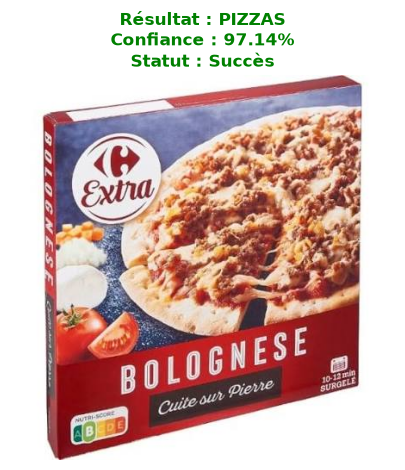


Détails du JSON renvoyé pour l'API :
{'rayon': 'pizzas', 'confiance': 97.13737487792969, 'statut': 'Succès'}


In [5]:
from PIL import Image
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd().parent))
from src.classifieur_images import predire_rayon_produit

# chemin_test = '../wip/img/yaourt-nature.png'
chemin_test = '../wip/img/pizza.jpg'

resultat = predire_rayon_produit(chemin_test)

try:
    plt.figure(figsize=(5, 5))
    img_visualisation = Image.open(chemin_test)
    plt.imshow(img_visualisation)
    
    # Choix de la couleur du titre selon le statut
    couleur_titre = "green" if resultat["statut"] == "Succès" else "darkred"
    
    titre_affichage = (
        f"Résultat : {resultat['rayon'].upper()}\n"
        f"Confiance : {resultat['confiance']:.2f}%\n"
        f"Statut : {resultat['statut']}"
    )
    
    plt.title(titre_affichage, fontsize=12, fontweight='bold', color=couleur_titre)
    plt.axis("off")
    plt.show()
    
    print("\nDétails du JSON renvoyé pour l'API :")
    print(resultat)

except Exception as e:
    print(f"Impossible d'afficher l'image : {e}")
